# Market edge cases: one step, round numbers

Single market steps with numbers small enough to check by hand. Each section plays
a situation, shows what every participant paid and why, and says what the market
does and what stays open. Nothing here changes the market: the notebook only plays
[`LocalEnergyMarket`](../../../core/market/lem.py) and reads its records. The first
version of this notebook found ten points; the ones decided on 11 Nov 2026 are
implemented, and the sections show the market after them.

**The setup, the same in every case**

- The 13 participants of the earlier thesis network, rural3
  ([`thesis_rural3_p13.json`](../../../config/archive/scenarios/thesis_rural3_p13.json),
  archived): who hangs on which feeder and how far apart is its geometry. The thesis
  scenario is now rural1
  ([`thesis_rural1.json`](../../../config/scenarios/thesis_rural1.json)); the rules are
  the same, the numbers differ (its transformer's no-load loss is 0.46 kW, rural3's
  1.26 kW). Every participant's generation and demand is set to 0 except the ones a
  case names.
- Flat tariffs: the DSO buys at **0.08** (feed-in tariff) and sells at **0.30**
  (utility price), EUR per kWh. One step is one hour, so kWh and kW are the same number.
- The imbalance fee is **off**, as in the thesis scenario (MP-4m); section 3 switches
  it on. Everything else as in that scenario's DSO: fees from the power flow.
- Batteries, where a case uses one: **10 kWh, 5 kW**, usable between 1 and 9 kWh,
  efficiency 0.95 each way, starting at 5 kWh.
- The network's other loads (the background) run as in SimBench, at midnight of
  15 June 2016.

**How to read a case**

Two tables per case. The first has one row per participant: what it ordered, where
the energy went (`peer`, `dso`, `untraded`; + is energy it received), and the money
(+ is money it received). `bill` is the step's reward:
`trades + fees + loss charge + untraded`. The second table has one row per trade
with the parts of its fee ([P1] eq. 8); stage 4 rows are the energy no trade covered,
settled with the DSO, which pays the fees of a DSO trade (MP-1f). A fee is never
negative: the zone bonus only cancels other fee parts (MP-4n).

| Section | What it shows | State |
|---|---|---|
| [0](#0.-What-behaves-as-documented) | Order limits, clearing stages, battery arithmetic | none |
| [1](#1.-The-loss-charge-near-a-balanced-network) | The loss charge no longer explodes when the network balances | fixed, MP-4k |
| [2](#2.-The-same-flow,-three-costs) | Untraded, peer-traded and DSO-cleared energy and their fees | fixed, MP-1f |
| [3](#3.-The-imbalance-fee) | The imbalance fee depends on other orders and flips at balance | off in the thesis scenario, MP-4m (open) |
| [4](#4.-Who-pays-for-a-loaded-line) | Who pays for a loaded line | fixed, MP-1f, MP-4l |
| [5](#5.-Voltage-breaks-first) | The fees see the limit that is reached first | fixed, MP-4l; levels open, MP-4f, MP-4i |
| [6](#6.-The-zone-bonus) | A same-feeder trade is no longer paid | fixed, MP-4n |
| [7](#7.-Peer-prices-outside-the-tariffs) | The market accepts them | open, MP-2b, MP-2e |
| [8](#8.-The-buy-limit-and-own-surplus) | Buying while exporting | fixed, MP-2f |
| [9](#9.-Smaller-ones) | Stored energy, ties, tiny orders | MP-1c open; MP-2g fixed |

In [1]:
import sys
from copy import deepcopy
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "core" / "market").is_dir())
sys.path.insert(0, str(ROOT))

import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from core.config import store
from core.config.scenario import BatterySetup
from core.env.reward import net_bill
from core.market.dso import DSO_ID
from core.market.lem import LocalEnergyMarket, OrderIntent

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BASE = store.load(ROOT / "config" / "archive" / "scenarios" / "thesis_rural3_p13.json")  # read only
BATTERY = BatterySetup(capacity_kwh=10.0, max_power_kw=5.0)
FEE_PARTS = ["congestion", "thermal", "voltage", "transmission", "zone", "imbalance", "peer_charge"]

# The imbalance fee is 15 % in this scenario (the thesis scenario switches it off, MP-4m)
FEE_ON = {"imbalance_factor": 0.15}


def sell(pid, kwh, price, partner=None):
    return OrderIntent(pid, False, price, kwh, partner)


def buy(pid, kwh, price, partner=None):
    return OrderIntent(pid, True, price, kwh, partner)

In [2]:
def market(gen=None, dem=None, soc=None, dso=None, grid=None, mkt=None, batteries=("P2", "P6", "P9")):
    # The thesis market with flat tariffs and everyone silent except gen / dem.
    # gen, dem: {participant: kWh per step}; soc: {participant: battery kWh at the start};
    # dso, grid, mkt: settings to change (DsoSetup, GridSetup, MarketSetup).
    s = deepcopy(BASE)
    s.dso.prices = {"utility": 0.30, "feed_in": 0.08}
    s.dso.imbalance_factor = 0.0  # as in the thesis scenario (MP-4m); section 3 switches it on
    s.market.partner_preference = False

    for key, value in (dso or {}).items():
        setattr(s.dso, key, value)

    for key, value in (grid or {}).items():
        setattr(s.grid, key, value)

    for key, value in (mkt or {}).items():
        setattr(s.market, key, value)

    for p in s.participants:
        p.battery = deepcopy(BATTERY) if p.id in batteries else None

    m = LocalEnergyMarket(s)
    m.reset()

    for pid, p in m.participants.items():
        steps = len(p.generation_kwh)
        p.generation_kwh = [float((gen or {}).get(pid, 0.0))] * steps
        p.demand_kwh = [float((dem or {}).get(pid, 0.0))] * steps

    for pid, kwh in (soc or {}).items():
        m.participants[pid].battery.energy_kwh = kwh

    return m


def step(m, orders=()):
    # Play one step with the given orders.
    return m.step({o.participant_id: o for o in orders})


def people(record, orders=(), who=None):
    # One row per participant: order, energy and money of the step.
    given = {o.participant_id: o for o in orders}
    placed = {o.agent_id: o for o in record.orders}
    fit, utility = record.inputs.feed_in_tariff, record.inputs.utility_price
    rows = []

    for pid, o in record.participants.items():
        active = o.generation_kwh or o.demand_kwh or o.soc_kwh is not None and pid in (who or ())
        if who is None and not (active or pid in given):
            continue
        if who is not None and pid not in who:
            continue

        mine = [t for t in record.trades if pid in (t.buyer_id, t.seller_id)]
        sign = lambda t: 1 if t.buyer_id == pid else -1
        i, v = given.get(pid), placed.get(pid)
        rows.append({
            "id": pid,
            "G": o.generation_kwh,
            "D": o.demand_kwh,
            "order": "-" if i is None else f"{'buy' if i.is_buy else 'sell'} {i.quantity_kwh:g} @ {i.price:g}"
                     + (f" -> {i.partner_id}" if i.partner_id else ""),
            "placed": "-" if i is None else ("nothing" if v is None else f"{v.quantity:.4g} @ {v.price:g}"),
            "peer": sum(sign(t) * t.quantity for t in mine if t.stage < 3),
            "dso": sum(sign(t) * t.quantity for t in mine if t.stage == 3),
            "untraded": -o.external_kwh,
            "battery after": o.soc_kwh,
            "trades EUR": -sum(sign(t) * t.price * t.quantity for t in mine),
            "fees EUR": -(o.fees - o.loss_charge),
            "loss charge EUR": -o.loss_charge,
            "untraded EUR": fit * o.deferred_supply_kwh - utility * o.deferred_demand_kwh,
            "bill EUR": net_bill(record, pid),
        })

    table = pd.DataFrame(rows).set_index("id")
    return table.dropna(axis=1, how="all")


def trades(record):
    # One row per trade, with the parts of its fee (eq. 8).
    rows = []

    for t in (*record.trades, *record.untraded):
        row = {
            "stage": t.stage,  # 4: the energy no trade covered, settled with the DSO
            "seller": t.seller_id,
            "buyer": t.buyer_id,
            "kWh": t.quantity,
            "price": t.price,
            "value EUR": t.quantity * t.price,
            "km": t.distance,
        }
        row.update({part: getattr(t.fee_parts, part) for part in FEE_PARTS})
        row.update({"fee EUR": t.fees, "buyer pays": t.buyer_fee, "seller pays": t.seller_fee})
        rows.append(row)

    table = pd.DataFrame(rows)
    quiet = [part for part in FEE_PARTS if part in table and (table[part].abs() < 1e-12).all()]
    return table.drop(columns=quiet)


def facts(record):
    # The step in one line: the loading and voltage the fees read, the money check.
    g = record.grid
    paid = sum(o.profit for o in record.participants.values())
    return (f"lines {g.max_line_loading_percent:.1f} %, transformer {g.max_trafo_loading_percent:.1f} %, "
            f"highest voltage {g.max_voltage_pu:.3f} pu, "
            f"network losses: {g.losses_kwh:.2f} kWh, "
            f"participants {paid:+.4f} + DSO {record.dso.profit:+.4f} = {paid + record.dso.profit:+.4f} EUR")


def case(title, orders=(), who=None, **setup):
    # Build the market, play one step, show both tables. Returns (market, record).
    m = market(**setup)
    record = step(m, orders)
    display(Markdown(f"**{title}**"))
    display(people(record, orders, who).round(4))
    if record.trades:
        display(trades(record).round(4))
    for note in record.notes:
        print("validation:", note)
    print(facts(record))
    return m, record


# Charts: one look for all of them
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#1a1a19", "#6b6a63", "#e4e3dc"


def axes(title, xlabel, ylabel, width=7.5, height=3.6):
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel(xlabel, color=MUTED)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    return fig, ax

## 0. What behaves as documented

Four cases with nothing to decide, to show the tables and the basic mechanics.

**Who is where.** P3 and P5 hang on the same feeder, 8 m apart. P4 is on another
feeder, 200 m from P3 along the lines.

In [3]:
# P3 has a surplus of 4 kWh (generates 5, uses 1). P5 needs 3, P4 needs 2.
# P3 asks 0.15, P5 bids 0.25: they meet at the average, 0.20. P4 places no order.
HOUSES = dict(gen={"P3": 5}, dem={"P3": 1, "P5": 3, "P4": 2})

_ = case("A peer trade, a rest for the DSO, and one participant without an order",
         orders=[sell("P3", 4, 0.15), buy("P5", 3, 0.25)], **HOUSES)

**A peer trade, a rest for the DSO, and one participant without an order**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.15,4 @ 0.15,-3,-1,-0.0,0.68,-0.0003,-0.0,0.0,0.6797
P4,0.0,2.0,-,-,0,0,2.0,0.00,-0.0027,-0.0,-0.6,-0.6027
P5,0.0,3.0,buy 3 @ 0.25,3 @ 0.25,3,0,-0.0,-0.60,-0.0000,-0.0,0.0,-0.6000


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P3,P5,3.0,0.20,0.60,0.0084,0.0004,0.0002,-0.0005,0.0000,0.0000,0.0000
1,3,P3,DSO,1.0,0.08,0.08,0.0921,0.0000,0.0002,0.0000,0.0003,0.0000,0.0003
2,4,DSO,P4,2.0,0.30,0.60,0.1075,0.0008,0.0019,0.0000,0.0027,0.0027,0.0000


lines 2.4 %, transformer 3.3 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants +0.0770 + DSO -0.0770 = -0.0000 EUR

Reading it: P3 sold 3 kWh to P5 at 0.20 (stage 2, the auction) and its last 1 kWh
to the DSO at 0.08 (stage 3). P4 placed no order, so its 2 kWh came from the grid
untraded at 0.30, settled with the DSO as a stage 4 trade that pays the fees of a DSO
trade (section 2). The peer trade's fee is **0**: the same-feeder bonus (`zone`, 15 %
of the trade's value) cancels its other fee parts but never pays out. More on that in
[section 6](#6.-The-zone-bonus).

In [4]:
_ = case("Orders beyond what a participant has: cut to its surplus and deficit",
         orders=[sell("P3", 10, 0.15), buy("P5", 10, 0.25)], **HOUSES)

_ = case("Orders on the wrong side (P3 has a surplus and buys, P5 has a deficit and sells): dropped",
         orders=[buy("P3", 2, 0.25), sell("P5", 2, 0.15)], **HOUSES)

_ = case("P3 and P5 name each other, but the bid is below the ask: no stage 1, P3 trades with P4 in the auction",
         orders=[sell("P3", 4, 0.25, "P5"), buy("P5", 3, 0.15, "P3"), buy("P4", 2, 0.28)], **HOUSES)

**Orders beyond what a participant has: cut to its surplus and deficit**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 10 @ 0.15,4 @ 0.15,-3.0,-1.0,-0.0,0.68,-0.0003,-0.0,0.0,0.6797
P4,0.0,2.0,-,-,0.0,0.0,2.0,0.00,-0.0027,-0.0,-0.6,-0.6027
P5,0.0,3.0,buy 10 @ 0.25,3 @ 0.25,3.0,0.0,-0.0,-0.60,-0.0000,-0.0,0.0,-0.6000


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P3,P5,3.0,0.20,0.60,0.0084,0.0004,0.0002,-0.0005,0.0000,0.0000,0.0000
1,3,P3,DSO,1.0,0.08,0.08,0.0921,0.0000,0.0002,0.0000,0.0003,0.0000,0.0003
2,4,DSO,P4,2.0,0.30,0.60,0.1075,0.0008,0.0019,0.0000,0.0027,0.0027,0.0000


validation:

P3: 10.00 kWh limited to 4.00

validation:

... (9 outputs left out)

**P3 and P5 name each other, but the bid is below the ask: no stage 1, P3 trades with P4 in the auction**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.25 -> P5,4 @ 0.25,-2,-2,-0.0,0.69,-0.0025,-0.0,0.0,0.6875
P4,0.0,2.0,buy 2 @ 0.28,2 @ 0.28,2,0,-0.0,-0.53,-0.0019,-0.0,0.0,-0.5319
P5,0.0,3.0,buy 3 @ 0.15 -> P3,3 @ 0.15,0,3,-0.0,-0.90,-0.0033,-0.0,0.0,-0.9033


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,fee EUR,buyer pays,seller pays
0,2,P3,P4,2,0.265,0.53,0.1996,0.0007,0.0032,0.0039,0.0019,0.0019
1,3,P3,DSO,2,0.080,0.16,0.0921,0.0001,0.0004,0.0005,0.0000,0.0005
2,3,DSO,P5,3,0.300,0.90,0.1005,0.0005,0.0027,0.0033,0.0033,0.0000


lines 2.4 %, transformer 3.3 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants -0.7477 + DSO +0.7477 = +0.0000 EUR

**The battery.** A battery owner places no order for the battery itself: after its
trades, what is left at its bus charges or discharges the battery
([`Participant.settle`](../../../core/market/agent/der.py)). With 5 kWh stored and a
floor of 1 kWh, it can deliver $(5 - 1) \cdot 0.95 = 3.8$ kWh at the bus; with a
ceiling of 9 kWh it can take $(9 - 5) / 0.95 = 4.21$ kWh.

In [5]:
_ = case("Deficit 3 kWh, no order: the battery covers it (3 / 0.95 = 3.16 kWh leave the battery)",
         dem={"P2": 3}, soc={"P2": 5})

_ = case("Deficit 3 kWh, buys as much as it may: 3 for the load + 4.21 to fill the battery",
         orders=[buy("P2", 100, 0.30)], dem={"P2": 3}, soc={"P2": 5})

_ = case("Deficit 6 kWh, no order: the battery gives its 3.8, the other 2.2 come untraded",
         dem={"P2": 6}, soc={"P2": 5})

**Deficit 3 kWh, no order: the battery covers it (3 / 0.95 = 3.16 kWh leave the battery)**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,0.0,3.0,-,-,0,0,-0.0,1.8421,0,-0.0,-0.0,0.0,0.0


lines 1.4 %, transformer 3.1 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants +0.0000 + DSO +0.0000 = +0.0000 EUR

**Deficit 3 kWh, buys as much as it may: 3 for the load + 4.21 to fill the battery**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,0.0,3.0,buy 100 @ 0.3,7.211 @ 0.3,0,7.2105,-0.0,9.0,-2.1632,-0.037,-0.0,0.0,-2.2002


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,fee EUR,buyer pays,seller pays
0,3,DSO,P2,7.2105,0.3,2.1632,0.3975,0.0112,0.0258,0.037,0.037,0.0


... (2 outputs left out)

lines 5.1 %, transformer 4.8 %, highest voltage 1.025 pu, network losses: 1.31 kWh, participants -2.2002 + DSO +2.2002 = +0.0000 EUR

**Deficit 6 kWh, no order: the battery gives its 3.8, the other 2.2 come untraded**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,0.0,6.0,-,-,0,0,2.2,1.0,0,-0.0095,-0.0,-0.66,-0.6695


lines 2.5 %, transformer 3.6 %, highest voltage 1.025 pu, network losses: 1.28 kWh, participants -0.0095 + DSO +0.0095 = +0.0000 EUR

## 1. The loss charge near a balanced network

With `dso.losses = "bcdla"` (the `powerflow` arm of the thesis experiment), the
step's measured losses are shared among the participants by their currents, and
each pays its share at the utility price (MP-4j). No order is needed: the charge
follows what a participant physically did. The first version of this notebook found
that the charge exploded when the network balanced; it is fixed (MP-4k).

**The case.** P13 generates 60 kWh at the end of one feeder, P11 consumes on
another. Nobody places an order. Only P11's consumption changes from case to case.

In [6]:
BCDLA = {"losses": "bcdla"}

_ = case("P13 generates 60, P11 consumes 60", dso=BCDLA, gen={"P13": 60}, dem={"P11": 60})
_ = case("P13 generates 60, P11 consumes 44", dso=BCDLA, gen={"P13": 60}, dem={"P11": 44})

**P13 generates 60, P11 consumes 60**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P11,0.0,60.0,-,-,0,0,60.0,0,-3.2908,-0.3900,-18.0,-21.6808
P13,60.0,0.0,-,-,0,0,-60.0,0,-0.7362,-0.3617,4.8,3.7021


lines 32.9 %, transformer 3.7 %, highest voltage 1.046 pu, network losses: 3.77 kWh, participants -4.7787 + DSO +4.7787 = +0.0000 EUR

**P13 generates 60, P11 consumes 44**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P11,0.0,44.0,-,-,0,0,44.0,0,-0.8993,-0.2034,-13.2,-14.3027
P13,60.0,0.0,-,-,0,0,-60.0,0,-0.7385,-0.3696,4.8,3.6919


lines 30.6 %, transformer 0.9 %, highest voltage 1.046 pu, network losses: 3.16 kWh, participants -2.2108 + DSO +2.2108 = +0.0000 EUR

Look at `loss charge EUR`. With 60 against 60 and with 60 against 44, P13 pays about
0.37 EUR and P11 between 0.20 and 0.39: no credit, no sign flip. The sweep below shows
the whole picture: P13's charge hardly moves (its own line losses), P11's grows with
its consumption and with the losses it causes. The network's other loads use about
13 kWh in this hour, so the community is balanced, with nothing exchanged with the
upstream grid, when P11 consumes about 47: nothing happens there any more.

,exchange with upstream kWh,network losses kWh,P13 share kWh,P11 share kWh,P13 pays EUR,P11 pays EUR
P11 consumes kWh,,,,,,
0,-46.19,2.53,1.30,0.00,0.39,0.00
10,-36.17,2.54,1.29,0.03,0.39,0.01
20,-26.08,2.64,1.27,0.13,0.38,0.04
30,-15.91,2.80,1.26,0.30,0.38,0.09
40,-5.67,3.04,1.24,0.55,0.37,0.17
44,-1.55,3.16,1.23,0.68,0.37,0.20
46,0.51,3.23,1.23,0.74,0.37,0.22
48,2.58,3.30,1.23,0.81,0.37,0.24
50,4.65,3.37,1.22,0.89,0.37,0.27


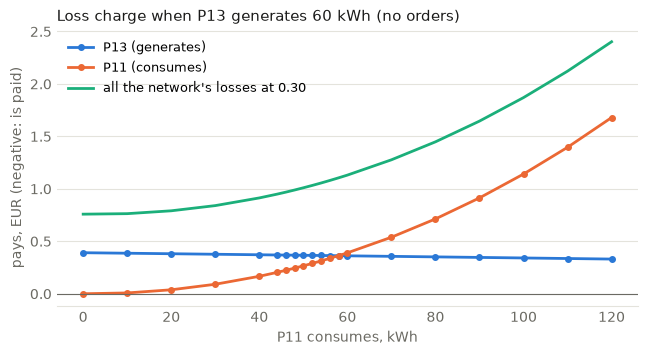

In [7]:
rows = []
for demand in list(range(0, 41, 10)) + list(range(44, 61, 2)) + list(range(70, 121, 10)):
    m = market(dso=BCDLA, gen={"P13": 60}, dem={"P11": demand})
    r = step(m)
    rows.append({
        "P11 consumes kWh": demand,
        "exchange with upstream kWh": r.grid.external_grid_kwh,
        "network losses kWh": r.grid.losses_kwh,
        "P13 share kWh": r.grid.loss_shares_kwh.get("P13", 0.0),
        "P11 share kWh": r.grid.loss_shares_kwh.get("P11", 0.0),
        "P13 pays EUR": r.participants["P13"].loss_charge,
        "P11 pays EUR": r.participants["P11"].loss_charge,
    })

sweep = pd.DataFrame(rows).set_index("P11 consumes kWh")
display(sweep.round(2))

fig, ax = axes("Loss charge when P13 generates 60 kWh (no orders)", "P11 consumes, kWh", "pays, EUR (negative: is paid)")
ax.plot(sweep.index, sweep["P13 pays EUR"], color=BLUE, linewidth=2, marker="o", markersize=4, label="P13 (generates)")
ax.plot(sweep.index, sweep["P11 pays EUR"], color=ORANGE, linewidth=2, marker="o", markersize=4, label="P11 (consumes)")
ax.plot(sweep.index, sweep["network losses kWh"] * 0.30, color=AQUA, linewidth=2, label="all the network's losses at 0.30")
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.legend(frameon=False, fontsize=9)
plt.show()

**What went wrong, and what changed.** The rule
([`BranchCurrentDecomposition.shares`](../../../core/grid/losses.py)) gives element $e$
this share of branch $b$'s loss:

$$
\text{share}_{e,b} = \frac{\operatorname{Re}\left(I_e \, \overline{I_b}\right)}{|I_b|^2} \cdot \text{loss}_b
$$

where $I_e$ is the element's current and $I_b$ the branch's, the sum of everything
below it. It comes from a loss that goes with the current squared, $R_b |I_b|^2$: then
$\text{loss}_b$ shrinks together with $|I_b|^2$ and the share stays small. A
**transformer** loses energy in two ways:

- the **copper loss**, $R |I|^2$: the current heats the windings, zero when nothing
  flows;
- the **no-load (iron) loss**: the iron core is magnetised as long as the transformer
  is switched on, whatever flows. "No load" does not mean nobody does anything in
  the network; it means this part is there even with zero current. Here it is
  1.26 kW, 30 kWh a day.

The old code shared the transformer's whole measured loss. Its constant 1.26 kW did
not shrink with $|I_b|$, so as the community balanced and $|I_b|$ went to zero the
ratio $I_e / I_b$ became very large: the table below shows credits and charges of
10 to 14 kW out of a 1.26 kW loss. Now only the copper loss is shared; the no-load
loss stays with the DSO. The next cell shows the transformer's part alone, with the
old rule and the new one.

In [8]:
from core.grid import losses as loss_rules


def transformer_part(demand):
    # P13's and P11's share of the transformer's loss alone, kW: sharing its whole
    # measured loss (the old rule) against only its copper loss (the rule now)
    m = market(dso=BCDLA, gen={"P13": 60}, dem={"P11": demand})
    step(m)
    net = m.grid._net
    current = loss_rules._element_currents(net)
    below = loss_rules._elements_below(net, current)
    measured = loss_rules.branch_losses_kw(net)[("trafo", 0)]
    copper = loss_rules.trafo_copper_losses_kw(net)[("trafo", 0)]
    mine = below[("trafo", 0)]
    total = sum((current[e] for e in mine), 0j)
    ratio = sorted(((current[e] * total.conjugate()).real / abs(total) ** 2 for e in mine))
    return {"P11 consumes kWh": demand, "|I_b| per unit": abs(total),
            "measured loss kW": measured, "of which copper kW": copper, "no-load kW": measured - copper,
            "old: largest credit kW": ratio[0] * measured, "old: largest share kW": ratio[-1] * measured,
            "now: largest credit kW": ratio[0] * copper, "now: largest share kW": ratio[-1] * copper}


display(pd.DataFrame([transformer_part(d) for d in (0, 40, 44, 48, 50, 60, 120)]).set_index("P11 consumes kWh").round(3))


,|I_b| per unit,measured loss kW,of which copper kW,no-load kW,old: largest credit kW,old: largest share kW,now: largest credit kW,now: largest share kW
P11 consumes kWh,,,,,,,,
0,0.046,1.325,0.064,1.26,-0.027,1.635,-0.001,0.080
40,0.007,1.262,0.002,1.26,-6.450,9.394,-0.008,0.012
44,0.004,1.261,0.000,1.26,-10.508,14.007,-0.003,0.005
48,0.003,1.261,0.000,1.26,-10.564,9.042,-0.002,0.002
50,0.004,1.261,0.001,1.26,-13.134,11.508,-0.005,0.005
60,0.014,1.266,0.006,1.26,-5.159,5.397,-0.023,0.024
120,0.076,1.434,0.175,1.26,-1.079,2.304,-0.131,0.280


The measured loss is 1.26 kW or more in every row, of which only the copper part
(0.00 to 0.18 kW) depends on the current. With the old rule the largest single share
was 14 kW; now it is at most 0.28 kW, always below the loss itself. **On the thesis
days this had not happened**: without orders, the closest the exchange with upstream
came to zero on 15 and 16 June and 1 July was 4.7 kWh. It was a latent case, reached
when the community's generation and consumption cancel within a step; on rural1 (11-17
June, the baseline rule) the median share per participant and step fell from 0.18 to
0.03 kWh, because the no-load part is no longer charged to anyone.

> **Decided (MP-4k).** Lines share their measured loss, a transformer its copper loss;
> the no-load loss is the DSO's (`LossShares.residual_kw`).

## 2. The same flow, three costs

P13 generates 60 kWh, P11 consumes 60 kWh. Physically the three cases below are
identical: the same power flows through the same lines. They differ only in what
the two wrote into the order book. Fees from the power flow, losses per trade
(`dso.losses = "trades"`, the default).

**no orders**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P11,0.0,60.0,-,-,0,0,60.0,0,-3.4375,-0.0,-18.0,-21.4375
P13,60.0,0.0,-,-,0,0,-60.0,0,-0.7786,-0.0,4.8,4.0214


lines 32.9 %, transformer 3.7 %, highest voltage 1.046 pu, network losses: 3.77 kWh, participants -4.2161 + DSO +4.2161 = +0.0000 EUR

**traded with each other at 0.20**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P11,0.0,60.0,buy 60 @ 0.2,60 @ 0.2,60,0,-0.0,-12.0,-1.1989,-0.0,0.0,-13.1989
P13,60.0,0.0,sell 60 @ 0.2,60 @ 0.2,-60,0,-0.0,12.0,-1.1989,-0.0,0.0,10.8011


,stage,seller,buyer,kWh,price,value EUR,km,thermal,voltage,transmission,fee EUR,buyer pays,seller pays
0,2,P13,P11,60,0.2,12.0,0.5662,1.9275,0.2664,0.2038,2.3977,1.1989,1.1989


... (2 outputs left out)

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P11,0.0,60.0,buy 60 @ 0.15,60 @ 0.15,0,60,-0.0,-18.0,-3.4375,-0.0,0.0,-21.4375
P13,60.0,0.0,sell 60 @ 0.25,60 @ 0.25,0,-60,-0.0,4.8,-0.7786,-0.0,0.0,4.0214


,stage,seller,buyer,kWh,price,value EUR,km,thermal,voltage,transmission,fee EUR,buyer pays,seller pays
0,3,P13,DSO,60,0.08,4.8,0.2947,0.6378,0.0984,0.0424,0.7786,0.0000,0.7786
1,3,DSO,P11,60,0.30,18.0,0.2715,2.8912,0.3996,0.1466,3.4375,3.4375,0.0000


lines 32.9 %, transformer 3.7 %, highest voltage 1.046 pu, network losses: 3.77 kWh, participants -17.4161 + DSO +17.4161 = +0.0000 EUR

,measured loading %,fees paid EUR,P13 bill EUR,P11 bill EUR,team bill EUR
situation,,,,,
no orders,32.85,4.22,4.02,-21.44,-17.42
traded with each other at 0.20,32.85,2.40,10.80,-13.20,-2.40
"both order, prices do not meet (DSO clears)",32.85,4.22,4.02,-21.44,-17.42


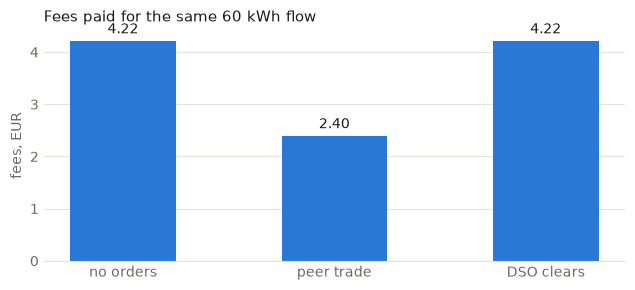

In [9]:
BIG = dict(gen={"P13": 60}, dem={"P11": 60})
situations = {
    "no orders": [],
    "traded with each other at 0.20": [sell("P13", 60, 0.20), buy("P11", 60, 0.20)],
    "both order, prices do not meet (DSO clears)": [sell("P13", 60, 0.25), buy("P11", 60, 0.15)],
}
rows = []
for name, orders in situations.items():
    m, r = case(name, orders=orders, **BIG)
    rows.append({
        "situation": name,
        "measured loading %": r.grid.max_line_loading_percent,
        "fees paid EUR": sum(o.fees for o in r.participants.values()),
        "P13 bill EUR": net_bill(r, "P13"),
        "P11 bill EUR": net_bill(r, "P11"),
        "team bill EUR": net_bill(r, "P13") + net_bill(r, "P11"),
    })

same_flow = pd.DataFrame(rows).set_index("situation")
display(same_flow.round(2))

fig, ax = axes("Fees paid for the same 60 kWh flow", "", "fees, EUR", height=3.0)
bars = ax.bar(["no orders", "peer trade", "DSO clears"], same_flow["fees paid EUR"], color=BLUE, width=0.5)
ax.bar_label(bars, fmt="%.2f", color=INK, padding=3)
plt.show()

Two things to see.

1. **The same flow pays the same fees whether it was ordered or not (MP-1f).** "No
   orders" and "DSO clears" cost the same to the cent: 4.22 EUR in fees and a team
   bill of -17.42. The energy no trade covers is settled with the DSO at the tariff
   (a stage 4 trade) and pays the fees of a DSO trade, along the same path. Not
   ordering was the cheapest answer to any fee while untraded energy paid none; it
   no longer is. The peer trade pays less (2.40 EUR): one trade at 0.20 between the
   two, instead of one with the DSO in each direction.
2. **Fees are a share of the trade's value**, quantity × price. In the third case
   the buyer's 60 kWh at 0.30 pay about four times the fee of the seller's 60 kWh
   at 0.08 (3.44 against 0.78 EUR), on a path of the same kind.

> **Decided (MP-1f).** Untraded energy pays the fees of a DSO trade, as the same
> energy ordered to the DSO does.

## 3. The imbalance fee

**Off in the thesis scenario** (`imbalance_factor` 0, MP-4m): the cases below switch it
on to show what it does. The published code never charged it (M-30); our reading
does, as follows. A trade with the DSO pays 15 % of its value, times $\min(q / |B|, 1)$,
when it "worsens" the order book's balance $B$ (offered minus asked;
[`Dso.imbalance_fee`](../../../core/market/dso.py), [P1] eq. 8b, 8h): the DSO
selling while more is offered than asked, or buying while more is asked than
offered. Untraded energy, settled with the DSO, pays it too.

**The case.** P3 offers 4 kWh at 0.25, P5 bids 0.15: the prices do not meet, so
the DSO clears both. P5 needs 6 kWh, so what it does not ask for is untraded. Only
P5's quantity changes.

In [10]:
ALMOST = dict(gen={"P3": 5}, dem={"P3": 1, "P5": 6}, dso=FEE_ON)

_ = case("P5 asks for 4.01 kWh: the book is short by 0.01",
         orders=[sell("P3", 4, 0.25), buy("P5", 4.01, 0.15)], **ALMOST)
_ = case("P5 asks for 3.99 kWh: the book is long by 0.01",
         orders=[sell("P3", 4, 0.25), buy("P5", 3.99, 0.15)], **ALMOST)

**P5 asks for 4.01 kWh: the book is short by 0.01**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.25,4 @ 0.25,0,-4.00,-0.00,0.320,-0.0492,-0.0,0.000,0.2708
P5,0.0,6.0,buy 4.01 @ 0.15,4.01 @ 0.15,0,4.01,1.99,-1.203,-0.0072,-0.0,-0.597,-1.8072


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,imbalance,fee EUR,buyer pays,seller pays
0,3,P3,DSO,4.00,0.08,0.320,0.0921,0.0003,0.0009,0.048,0.0492,0.0000,0.0492
1,3,DSO,P5,4.01,0.30,1.203,0.1005,0.0012,0.0036,0.000,0.0048,0.0048,0.0000
2,4,DSO,P5,1.99,0.30,0.597,0.1005,0.0006,0.0018,0.000,0.0024,0.0024,0.0000


lines 3.1 %, transformer 3.6 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants -0.9394 + DSO +0.9394 = +0.0000 EUR

**P5 asks for 3.99 kWh: the book is long by 0.01**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.25,4 @ 0.25,0,-4.00,-0.00,0.320,-0.0012,-0.0,0.000,0.3188
P5,0.0,6.0,buy 3.99 @ 0.15,3.99 @ 0.15,0,3.99,2.01,-1.197,-0.2772,-0.0,-0.603,-2.0772


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,imbalance,fee EUR,buyer pays,seller pays
0,3,P3,DSO,4.00,0.08,0.320,0.0921,0.0003,0.0009,0.0000,0.0012,0.0000,0.0012
1,3,DSO,P5,3.99,0.30,1.197,0.1005,0.0012,0.0036,0.1796,0.1844,0.1844,0.0000
2,4,DSO,P5,2.01,0.30,0.603,0.1005,0.0006,0.0018,0.0904,0.0929,0.0929,0.0000


lines 3.1 %, transformer 3.6 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants -1.1554 + DSO +1.1554 = +0.0000 EUR

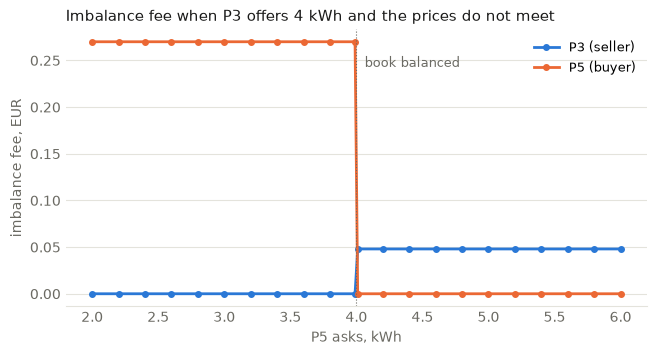

In [11]:
rows = []
for q in sorted([n / 10 for n in range(20, 61, 2) if n != 40] + [3.99, 4.01]):
    m = market(**ALMOST)
    r = step(m, [sell("P3", 4, 0.25), buy("P5", q, 0.15)])
    fee = {}
    for t in (*r.trades, *r.untraded):  # the untraded energy pays it too
        who = t.seller_id if t.buyer_id == DSO_ID else t.buyer_id
        fee[who] = fee.get(who, 0.0) + t.fee_parts.imbalance
    rows.append({"P5 asks kWh": q, "P3 (seller)": fee.get("P3", 0.0), "P5 (buyer)": fee.get("P5", 0.0)})

imbalance = pd.DataFrame(rows).set_index("P5 asks kWh")

fig, ax = axes("Imbalance fee when P3 offers 4 kWh and the prices do not meet", "P5 asks, kWh", "imbalance fee, EUR")
ax.plot(imbalance.index, imbalance["P3 (seller)"], color=BLUE, linewidth=2, marker="o", markersize=4, label="P3 (seller)")
ax.plot(imbalance.index, imbalance["P5 (buyer)"], color=ORANGE, linewidth=2, marker="o", markersize=4, label="P5 (buyer)")
ax.axvline(4, color=MUTED, linewidth=0.8, linestyle=":")
ax.annotate("book balanced", (4, imbalance.max().max() * 0.9), xytext=(6, 0), textcoords="offset points", ha="left", fontsize=9, color=MUTED)
ax.legend(frameon=False, fontsize=9)
plt.show()

At 4 kWh the fee jumps from one participant to the other (the two points next to the
line are 3.99 and 4.01 kWh): at 4.01 the seller P3 pays 0.05 EUR and P5 nothing, at
3.99 P5 pays 0.27 EUR, on its DSO purchase and on its untraded 2.01 kWh, and P3 almost
nothing. The scale $\min(q / |B|, 1)$ is largest when the book is balanced, so a change
of 0.02 kWh moves 15 % of the trade's value from one side to the other. And it
reaches a participant through **somebody else's** order: below, P3's fee on the 1 kWh
it sells to the DSO changes only because P4, on another feeder, adds a low bid.

In [12]:
_, without = case("P4 places no order", orders=[sell("P3", 4, 0.15), buy("P5", 3, 0.25)], dso=FEE_ON, **HOUSES)
_, with_p4 = case("P4 bids 0.10 for its 2 kWh (below every ask, so the DSO clears it)",
                  orders=[sell("P3", 4, 0.15), buy("P5", 3, 0.25), buy("P4", 2, 0.10)], dso=FEE_ON, **HOUSES)

**P4 places no order**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.15,4 @ 0.15,-3,-1,-0.0,0.68,-0.0003,-0.0,0.0,0.6797
P4,0.0,2.0,-,-,0,0,2.0,0.00,-0.0927,-0.0,-0.6,-0.6927
P5,0.0,3.0,buy 3 @ 0.25,3 @ 0.25,3,0,-0.0,-0.60,-0.0000,-0.0,0.0,-0.6000


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,imbalance,fee EUR,buyer pays,seller pays
0,2,P3,P5,3.0,0.20,0.60,0.0084,0.0004,0.0002,-0.0005,0.00,0.0000,0.0000,0.0000
1,3,P3,DSO,1.0,0.08,0.08,0.0921,0.0000,0.0002,0.0000,0.00,0.0003,0.0000,0.0003
2,4,DSO,P4,2.0,0.30,0.60,0.1075,0.0008,0.0019,0.0000,0.09,0.0927,0.0927,0.0000


lines 2.4 %, transformer 3.3 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants -0.0130 + DSO +0.0130 = -0.0000 EUR

**P4 bids 0.10 for its 2 kWh (below every ask, so the DSO clears it)**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.15,4 @ 0.15,-3,-1,-0.0,0.68,-0.0123,-0.0,0.0,0.6677
P4,0.0,2.0,buy 2 @ 0.1,2 @ 0.1,0,2,-0.0,-0.60,-0.0027,-0.0,0.0,-0.6027
P5,0.0,3.0,buy 3 @ 0.25,3 @ 0.25,3,0,-0.0,-0.60,-0.0000,-0.0,0.0,-0.6000


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,imbalance,fee EUR,buyer pays,seller pays
0,2,P3,P5,3,0.20,0.60,0.0084,0.0004,0.0002,-0.0005,0.000,0.0000,0.0000,0.0000
1,3,P3,DSO,1,0.08,0.08,0.0921,0.0000,0.0002,0.0000,0.012,0.0123,0.0000,0.0123
2,3,DSO,P4,2,0.30,0.60,0.1075,0.0008,0.0019,0.0000,0.000,0.0027,0.0027,0.0000


lines 2.4 %, transformer 3.3 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants -0.5350 + DSO +0.5350 = +0.0000 EUR

> **Decided for the thesis scenario (MP-4m): off.** The published code never charged
> it. In this form it is decided by the sign of a net that no agent sees (a central
> controller can steer by it, decentralised actors cannot) and a bigger imbalance
> gives a smaller fee. The code stays, marked `# OPEN MP-4m`. Open: keep it off, or
> replace it with a flat charge on the energy routed through the DSO, or a fee on
> $\min(q, |B|)$, which at least is continuous.

## 4. Who pays for a loaded line

The congestion and thermal parts of a trade's fee read the highest loading on the
lines **between the two traders** ([`Dso.fees_of`](../../../core/market/dso.py)); for
a trade or settlement with the DSO the transformer's loading counts too (MP-4l). The
loading comes from the power flow: everything on the network, whatever was traded.

**The case.** P13 exports 60 kWh **untraded** and loads its feeder. P10 sells
3 kWh to P12, 11 m apart on the same feeder.

In [13]:
LOADED = dict(gen={"P13": 60, "P10": 3}, dem={"P11": 60, "P12": 3}, batteries=())

m, r = case("P13's 60 kWh untraded, P10 sells 3 kWh to P12",
            orders=[sell("P10", 3, 0.20), buy("P12", 3, 0.20)], **LOADED)
local = next(t for t in r.trades if t.stage < 3)
display(pd.DataFrame([{
    "loading the fees read %": r.grid.max_line_loading_percent,
    "transformer %": r.grid.max_trafo_loading_percent,
    "thermal fee of the 3 kWh trade": local.fee_parts.thermal,
    "as share of its value": local.fee_parts.thermal / (local.quantity * local.price),
    "fees P13 pays": r.participants["P13"].fees,
}]).round(4))


**P13's 60 kWh untraded, P10 sells 3 kWh to P12**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P10,3.0,0.0,sell 3 @ 0.2,3 @ 0.2,-3,0,-0.0,0.6,-0.0036,-0.0,0.0,0.5964
P11,0.0,60.0,-,-,0,0,60.0,0.0,-3.4375,-0.0,-18.0,-21.4375
P12,0.0,3.0,buy 3 @ 0.2,3 @ 0.2,3,0,-0.0,-0.6,-0.0036,-0.0,0.0,-0.6036
P13,60.0,0.0,-,-,0,0,-60.0,0.0,-0.8529,-0.0,4.8,3.9471


,stage,seller,buyer,kWh,price,value EUR,km,thermal,voltage,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P10,P12,3.0,0.20,0.6,0.0112,0.0889,0.0081,0.0002,-0.09,0.0073,0.0036,0.0036
1,4,DSO,P11,60.0,0.30,18.0,0.2715,2.8912,0.3996,0.1466,0.00,3.4375,3.4375,0.0000
2,4,P13,DSO,60.0,0.08,4.8,0.2947,0.7116,0.0989,0.0424,0.00,0.8529,0.0000,0.8529


lines 32.9 %, transformer 3.7 %, highest voltage 1.046 pu, network losses: 3.77 kWh, participants -4.2976 + DSO +4.2976 = +0.0000 EUR

,loading the fees read %,transformer %,thermal fee of the 3 kWh trade,as share of its value,fees P13 pays
0,32.85,3.74,0.0889,0.1482,0.8529


The small local trade pays a thermal fee for a loading it did not cause (0.09 EUR,
15 % of its value; the same-feeder bonus cancels it, so the trade pays 0.01 in
all). P13, who caused the loading, now pays too: 0.85 EUR on its untraded 60 kWh
(18 % of the 4.80 EUR they earn), the fee of a DSO trade (MP-1f). Before, P13 paid
nothing.

**Does the choice of partner matter?** P7 needs 60 kWh. P13, 29 m away on the same
feeder, and P1, on another feeder, both generate 60 kWh. P7 buys from one or the
other; the flows are the same either way.

In [14]:
CHOICE = dict(gen={"P13": 60, "P1": 60}, dem={"P7": 60})
rows = []
for seller, where in (("P1", "another feeder"), ("P13", "its neighbour")):
    m = market(**CHOICE)
    r = step(m, [sell(seller, 60, 0.20), buy("P7", 60, 0.20)])
    t = next(t for t in r.trades if t.stage < 3)
    row = {"P7 buys from": f"{seller}, {where}", "loading %": r.grid.max_line_loading_percent,
           "transformer %": r.grid.max_trafo_loading_percent}
    row.update({part: getattr(t.fee_parts, part) for part in ("congestion", "thermal", "voltage", "transmission", "zone")})
    row["fee EUR"] = t.fees
    rows.append(row)

display(pd.DataFrame(rows).set_index("P7 buys from").round(3))


,loading %,transformer %,congestion,thermal,voltage,transmission,zone,fee EUR
P7 buys from,,,,,,,,
"P1, another feeder",31.17,11.73,0.0,1.642,0.113,0.136,-0.000,1.891
"P13, its neighbour",31.17,11.73,0.0,1.676,0.032,0.010,-1.718,0.000


The thermal part is almost the same for both partners (1.64 and 1.68 EUR), because
the lines carry the same power whoever is named. What separates the two is the
same-feeder bonus: it would be 15 % of the trade's value (1.8 EUR), and it cancels the
neighbour's other fees completely (-1.72 EUR, capped at them, MP-4n), so that trade
pays nothing, while the one across feeders pays 1.89 EUR.

In [15]:
rows = []
for kwh in (5, 10, 20, 40, 60, 80, 100):
    m = market(gen={"P13": kwh}, dem={"P11": kwh})
    r = step(m, [sell("P13", kwh, 0.20), buy("P11", kwh, 0.20)])
    t = next(t for t in r.trades if t.stage < 3)
    value = t.quantity * t.price
    row = {"trade kWh": kwh,
           "lines %": r.grid.max_line_loading_percent,
           "transformer %": r.grid.max_trafo_loading_percent,
           "highest voltage pu": r.grid.max_voltage_pu,
           "violations": len(r.grid.violations),
           "fee, share of value": t.fees / value}
    row.update({part: getattr(t.fee_parts, part) / value for part in ("congestion", "thermal", "voltage", "transmission")})
    rows.append(row)

sizes = pd.DataFrame(rows).set_index("trade kWh")
display(sizes.round(4))


,lines %,transformer %,highest voltage pu,violations,"fee, share of value",congestion,thermal,voltage,transmission
trade kWh,,,,,,,,,
5,3.47,3.10,1.0258,0,0.0197,0.0,0.0000,0.0027,0.017
10,6.09,3.11,1.0276,0,0.0214,0.0,0.0000,0.0044,0.017
20,11.36,3.17,1.0313,0,0.0249,0.0,0.0000,0.0079,0.017
40,22.03,3.38,1.0385,0,0.0573,0.0,0.0254,0.0149,0.017
60,32.85,3.74,1.0455,0,0.1998,0.0,0.1606,0.0222,0.017
80,43.83,4.24,1.0524,4,0.3445,0.0,0.2979,0.0296,0.017
100,54.98,4.89,1.0592,9,0.3542,0.0,0.3000,0.0372,0.017


## 5. Voltage breaks first

The same sweep as before, read for the network's limits and for the parts of the fee.
The limits are 100 % line loading and voltages between 0.95 and 1.05 pu. The voltage
part of a fee is now the largest deviation on the trade's path from the voltage the
network is held at, the external grid's set point of 1.025 pu,
$\max |V - V_\text{slack}|$, not the difference between its two ends (MP-4l).

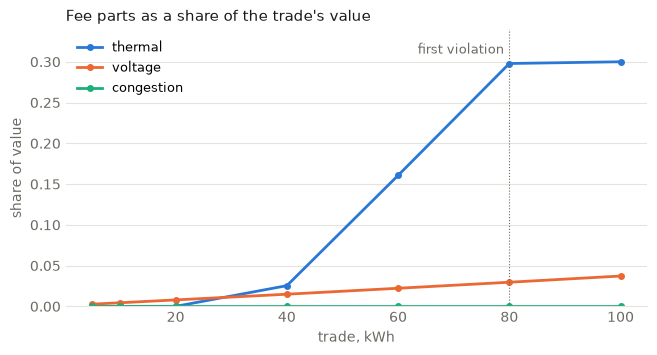

In [16]:
fig, ax = axes("Fee parts as a share of the trade's value", "trade, kWh", "share of value")
for part, color in (("thermal", BLUE), ("voltage", ORANGE), ("congestion", AQUA)):
    ax.plot(sizes.index, sizes[part], color=color, linewidth=2, marker="o", markersize=4, label=part)
if (sizes["violations"] > 0).any():
    first = sizes.index[sizes["violations"] > 0].min()
    ax.axvline(first, color=MUTED, linewidth=0.8, linestyle=":")
    ax.annotate("first violation", (first, 0.31), xytext=(-4, 0), textcoords="offset points", ha="right", fontsize=9, color=MUTED)
ax.set_ylim(0, 0.34)
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.show()


- The **voltage** limit is passed at 80 kWh (1.052 pu), with the lines at 44 % and the
  transformer at 4 %.
- The **voltage** part of the fee is $|V - V_\text{slack}|$ on the path, capped at 5 % of
  the value (`voltage_threshold`). It is **0.3 % for a 5 kWh trade** and 3.0 % when
  the limit is passed (the limit, 1.05 pu, is 0.025 from the slack), so a quiet network
  pays nothing. Read from nominal 1 pu it was 2.6 % already for 5 kWh, because the
  external grid sits at 1.025 pu. The cap is 0.05 pu from the slack and is not reached.
- The **thermal** part starts at 20 % loading and is at its 30 % cap by 44 %.
- The **congestion** part starts at 80 % loading, which 100 kWh does not reach.

So the fee that grows with the trade is the thermal one, and it stops growing about
where the first violation appears.

> **Open (MP-4f, MP-4i).** The fee levels: thresholds placed against lines that stay
> far below their limits (the thesis scenario's thermal threshold is 0.8, a first choice).
> Do they price the limits the stress scenario reaches?

## 6. The zone bonus

A trade between two participants on the same feeder gets a bonus of $0.15 \cdot q \cdot p$
(`zone`, [P1] eq. 8e; M-33, M-34). It **cancels fees but never pays out** (MP-4n):
the bonus is at most the sum of the trade's other fee parts, so no fee is negative.
Before, the total could be negative and the DSO paid the two traders.

**The case.** P2 and P6 are 4 m apart on one feeder, each with a battery at 5 kWh
and nothing else: no load, no generation. They pass energy back and forth at 0.30,
as much as the batteries allow, swapping roles every step.

**One trade: P2 sells 3 kWh from its battery to P6 at 0.20**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,0.0,0.0,sell 3 @ 0.2,3 @ 0.2,-3,0,-0.0,1.8421,0.6,-0.0,-0.0,0.0,0.6
P6,0.0,0.0,buy 3 @ 0.2,3 @ 0.2,3,0,-0.0,7.8500,-0.6,-0.0,-0.0,0.0,-0.6


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P2,P6,3,0.2,0.6,0.0036,0.0008,0.0001,-0.0009,0.0,0.0,0.0


lines 1.8 %, transformer 3.1 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants +0.0000 + DSO +0.0000 = +0.0000 EUR

,seller,traded kWh,bought from DSO kWh,P2 battery,P6 battery,P2 bill,P6 bill,DSO has paid out EUR
step,,,,,,,,
0,P2,3.800,0.411,1.00,9.000,1.140,-1.265,0.0
1,P6,5.000,0.000,5.75,3.737,-1.500,1.500,0.0
2,P2,4.512,0.487,1.00,8.487,1.354,-1.502,0.0
3,P6,5.000,0.000,5.75,3.224,-1.500,1.500,0.0
4,P2,4.512,0.487,1.00,7.974,1.354,-1.502,0.0
5,P6,5.000,0.000,5.75,2.711,-1.500,1.500,0.0
6,P2,4.512,0.487,1.00,7.461,1.354,-1.502,0.0
7,P6,5.000,0.000,5.75,2.197,-1.500,1.500,0.0
8,P2,4.512,0.487,1.00,6.947,1.354,-1.502,0.0


after 12 steps: bills together -0.87 EUR, 56.4 kWh traded, stored energy 10.0 -> 6.92 kWh

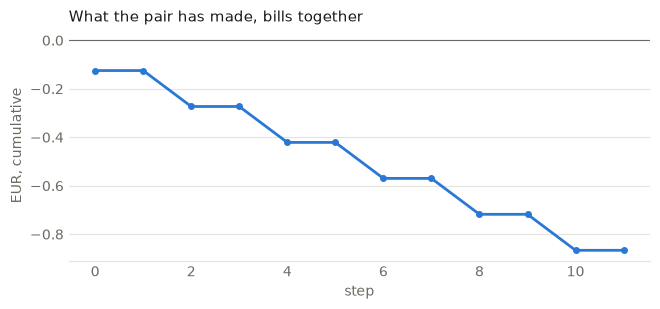

In [17]:
_ = case("One trade: P2 sells 3 kWh from its battery to P6 at 0.20",
         orders=[sell("P2", 3, 0.20), buy("P6", 3, 0.20)], soc={"P2": 5, "P6": 5})

m = market(soc={"P2": 5, "P6": 5})
rows, paid_out, stored = [], 0.0, None
for n in range(12):
    seller, buyer = ("P2", "P6") if n % 2 == 0 else ("P6", "P2")
    r = step(m, [sell(seller, 100, 0.30), buy(buyer, 100, 0.30)])
    paid_out += -sum(t.fees for t in r.trades if t.stage < 3)
    rows.append({
        "step": n,
        "seller": seller,
        "traded kWh": r.p2p_kwh,
        "bought from DSO kWh": r.dso_kwh,
        "P2 battery": r.participants["P2"].soc_kwh,
        "P6 battery": r.participants["P6"].soc_kwh,
        "P2 bill": net_bill(r, "P2"),
        "P6 bill": net_bill(r, "P6"),
        "DSO has paid out EUR": paid_out,
    })

wash = pd.DataFrame(rows).set_index("step")
display(wash.round(3))
print(f"after 12 steps: bills together {wash['P2 bill'].sum() + wash['P6 bill'].sum():+.2f} EUR, "
      f"{wash['traded kWh'].sum():.1f} kWh traded, stored energy {5 + 5:.1f} -> "
      f"{wash['P2 battery'].iloc[-1] + wash['P6 battery'].iloc[-1]:.2f} kWh")

pair = (wash["P2 bill"] + wash["P6 bill"]).cumsum()
fig, ax = axes("What the pair has made, bills together", "step", "EUR, cumulative", height=3.0)
ax.plot(wash.index, pair, color=BLUE, linewidth=2, marker="o", markersize=4)
ax.axhline(0, color=MUTED, linewidth=0.8)
plt.show()

The energy only moves between two batteries and loses about 10 % each round trip
(stored energy falls from 10.0 to 6.9 kWh, with 2.8 kWh bought from the DSO on the
way), and the pair ends 0.87 EUR **behind**: the DSO has paid out nothing, since the
bonus only cancels the small fees of a trade between neighbours. Before the fix the
same pair ended 1.67 EUR ahead, paid 2.53 EUR in bonuses.

> **Decided (MP-4n).** The bonus lowers a trade's fee to 0 and no lower.

## 7. Peer prices outside the tariffs

The market limits an order's price to its own range, 0 to 1
([`LocalEnergyMarket._validate`](../../../core/market/lem.py)), not to the DSO's
tariffs. Two peers can therefore trade above the utility price or below the
feed-in tariff.

A trained agent cannot do this: [`MarketEnv.decode`](../../../core/env/market_env.py)
maps its price into the range from the feed-in tariff to the peer ceiling. It can
only come from scripted orders or a bidding rule.

In [18]:
_ = case("P3 asks 0.50, P5 bids 0.90: they trade at 0.70, with the DSO selling at 0.30",
         orders=[sell("P3", 4, 0.50), buy("P5", 3, 0.90)], gen={"P3": 5}, dem={"P3": 1, "P5": 3})
_ = case("P3 asks 0.01, P5 bids 0.05: they trade at 0.03, with the DSO buying at 0.08",
         orders=[sell("P3", 4, 0.01), buy("P5", 3, 0.05)], gen={"P3": 5}, dem={"P3": 1, "P5": 3})

**P3 asks 0.50, P5 bids 0.90: they trade at 0.70, with the DSO selling at 0.30**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.5,4 @ 0.5,-3,-1,-0.0,2.18,-0.0003,-0.0,0.0,2.1797
P5,0.0,3.0,buy 3 @ 0.9,3 @ 0.9,3,0,-0.0,-2.10,-0.0000,-0.0,0.0,-2.1000


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P3,P5,3,0.70,2.10,0.0084,0.001,0.0005,-0.0016,0.0000,0.0,0.0000
1,3,P3,DSO,1,0.08,0.08,0.0921,0.000,0.0002,0.0000,0.0003,0.0,0.0003


lines 1.6 %, transformer 2.9 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants +0.0797 + DSO -0.0797 = +0.0000 EUR

**P3 asks 0.01, P5 bids 0.05: they trade at 0.03, with the DSO buying at 0.08**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.01,4 @ 0.01,-3,-1,-0.0,0.17,-0.0003,-0.0,0.0,0.1697
P5,0.0,3.0,buy 3 @ 0.05,3 @ 0.05,3,0,-0.0,-0.09,-0.0000,-0.0,0.0,-0.0900


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P3,P5,3,0.03,0.09,0.0084,0.0,0.0000,-0.0001,0.0000,0.0,0.0000
1,3,P3,DSO,1,0.08,0.08,0.0921,0.0,0.0002,0.0000,0.0003,0.0,0.0003


lines 1.6 %, transformer 2.9 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants +0.0797 + DSO -0.0797 = -0.0000 EUR

> **Open (MP-2b, MP-2e).** Limit order prices to the tariffs in the market as well, or
> leave that to the environment? Kept as it is; the market step page says what the
> market does with a price: it limits it to its own bounds, not to the tariffs.

## 8. The buy limit and own surplus

What a participant may buy is its deficit plus what its battery can take **after its
own surplus has filled it**:
$q_\text{buy,max} = \max(0, D - G) + \max\bigl(0,\ E_\text{chargeable} - \max(0, G - D)\bigr)$
([`Participant.max_buy_kwh`](../../../core/market/agent/der.py), MP-2f). [P1] eq. 15b
adds the whole room to a household that already has a surplus; the sell limit was
changed for the mirror case (MP-2c).

**The case.** P2 is given generation 6 and load 1 (surplus 5) and a battery at
5 kWh, which can take 4.21 kWh.

**In the thesis scenario no participant has both PV and a battery**, so this cannot
happen in the final runs.

In [19]:
SURPLUS = dict(gen={"P2": 6}, dem={"P2": 1}, soc={"P2": 5})

_ = case("No order: the surplus fills the battery, the rest is exported", **SURPLUS)
_ = case("Tries to buy as much as it may: its own surplus fills the battery, so the limit is 0",
         orders=[buy("P2", 100, 0.30)], **SURPLUS)

**No order: the surplus fills the battery, the rest is exported**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,6.0,1.0,-,-,0,0,-0.7895,9.0,0,-0.0008,-0.0,0.0632,0.0623


lines 1.4 %, transformer 2.9 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants -0.0008 + DSO +0.0008 = +0.0000 EUR

**Tries to buy as much as it may: its own surplus fills the battery, so the limit is 0**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,6.0,1.0,buy 100 @ 0.3,nothing,0,0,-0.7895,9.0,0,-0.0008,-0.0,0.0632,0.0623


validation:

P2: 100.00 kWh limited to 0.00

lines 1.4 %, transformer 2.9 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants -0.0008 + DSO +0.0008 = +0.0000 EUR

The battery ends at 9 kWh both times and the bill is the same: the order is cut to 0
(see the validation note). Before, the second case bought 4.21 kWh from the DSO at
0.30 while its own 5 kWh left at 0.08, and the bill was 0.94 EUR worse.

> **Decided (MP-2f).** The surplus counts against the buy limit, as MP-2c does on
> the sell side.

## 9. Smaller ones

**Stored energy is free in the bill (MP-1c).** The same deficit of 3 kWh: covered
from the battery it costs nothing, bought it costs 0.91 EUR (0.90 and 0.01 in fees)
and leaves the battery full. The bill does not see the 3.16 kWh the battery lost.

In [20]:
_ = case("Deficit 3 kWh, no order", dem={"P2": 3}, soc={"P2": 5})
_ = case("Deficit 3 kWh, buys 3 kWh", orders=[buy("P2", 3, 0.30)], dem={"P2": 3}, soc={"P2": 5})

**Deficit 3 kWh, no order**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,0.0,3.0,-,-,0,0,-0.0,1.8421,0,-0.0,-0.0,0.0,0.0


lines 1.4 %, transformer 3.1 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants +0.0000 + DSO +0.0000 = +0.0000 EUR

**Deficit 3 kWh, buys 3 kWh**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,0.0,3.0,buy 3 @ 0.3,3 @ 0.3,0,3,-0.0,5,-0.9,-0.0134,-0.0,0.0,-0.9134


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,fee EUR,buyer pays,seller pays
0,3,DSO,P2,3,0.3,0.9,0.3975,0.0027,0.0107,0.0134,0.0134,0.0


lines 2.9 %, transformer 3.8 %, highest voltage 1.025 pu, network losses: 1.28 kWh, participants -0.9134 + DSO +0.9134 = +0.0000 EUR

**Ties go to the participant listed first.** Two sellers at the same price and the
same reputation: the auction takes them in the scenario's order
([`Clearing.double_auction`](../../../core/market/clearing.py)). P1 sells, P3 is
left for the DSO.

In [21]:
_ = case("P1 and P3 both ask 0.15; P5 bids 0.25 for 3 kWh",
         orders=[sell("P3", 4, 0.15), sell("P1", 3, 0.15), buy("P5", 3, 0.25)],
         gen={"P3": 5, "P1": 3}, dem={"P3": 1, "P5": 3})

**P1 and P3 both ask 0.15; P5 bids 0.25 for 3 kWh**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P1,3.0,0.0,sell 3 @ 0.15,3 @ 0.15,-3,0,-0.0,0.60,-0.000,-0.0,0.0,0.600
P3,5.0,1.0,sell 4 @ 0.15,4 @ 0.15,0,-4,-0.0,0.32,-0.001,-0.0,0.0,0.319
P5,0.0,3.0,buy 3 @ 0.25,3 @ 0.25,3,0,-0.0,-0.60,-0.000,-0.0,0.0,-0.600


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P1,P5,3,0.20,0.60,0.0369,0.0001,0.0007,-0.0007,0.000,0.0,0.000
1,3,P3,DSO,4,0.08,0.32,0.0921,0.0002,0.0009,0.0000,0.001,0.0,0.001


lines 1.9 %, transformer 2.1 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants +0.3190 + DSO -0.3190 = +0.0000 EUR

**A tiny order is an order, unless the scenario says otherwise (MP-2g).** With
`min_quantity` 0, the default, an order of 0.0000001 kWh is placed: it enters the book
and the auction and trades nothing. With `min_quantity` 0.001 kWh, as in the thesis
scenario, it is dropped before it becomes an order (without a validation note). The
environment already drops orders below 5 % of the limit, so this needs a scripted order.

In [22]:
HOUSES_SMALL = dict(gen={"P3": 5}, dem={"P3": 1, "P5": 3})
_ = case("P5 places an order of 0.0000001 kWh (min_quantity 0, the scenario's default)",
         orders=[buy("P5", 1e-7, 0.25)], **HOUSES_SMALL)
_ = case("The same order with min_quantity 0.001 kWh (the thesis scenario)",
         orders=[buy("P5", 1e-7, 0.25)], mkt={"min_quantity": 0.001}, **HOUSES_SMALL)

**P5 places an order of 0.0000001 kWh (min_quantity 0, the scenario's default)**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,-,-,0,0,-4.0,0,-0.0011,-0.0,0.32,0.3189
P5,0.0,3.0,buy 1e-07 @ 0.25,1e-07 @ 0.25,0,0,3.0,0,-0.0033,-0.0,-0.90,-0.9033


lines 1.6 %, transformer 2.9 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants -0.0043 + DSO +0.0043 = +0.0000 EUR

**The same order with min_quantity 0.001 kWh (the thesis scenario)**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,-,-,0,0,-4.0,0,-0.0011,-0.0,0.32,0.3189
P5,0.0,3.0,buy 1e-07 @ 0.25,nothing,0,0,3.0,0,-0.0033,-0.0,-0.90,-0.9033


lines 1.6 %, transformer 2.9 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants -0.0043 + DSO +0.0043 = +0.0000 EUR

**Naming the DSO as partner still works in the market.** The environment no longer
offers it (RP-1h), but an order that names `DSO` skips the auction and goes
straight to stage 3, where it pays the fees of a DSO trade.

In [23]:
_ = case("P4 names the DSO; P3 could have sold to it",
         orders=[sell("P3", 4, 0.15), buy("P4", 2, 0.25, DSO_ID)], gen={"P3": 5}, dem={"P3": 1, "P4": 2})

**P4 names the DSO; P3 could have sold to it**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.15,4 @ 0.15,0,-4,-0.0,0.32,-0.0011,-0.0,0.0,0.3189
P4,0.0,2.0,buy 2 @ 0.25 -> DSO,2 @ 0.25,0,2,-0.0,-0.60,-0.0027,-0.0,0.0,-0.6027


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,fee EUR,buyer pays,seller pays
0,3,P3,DSO,4,0.08,0.32,0.0921,0.0002,0.0009,0.0011,0.0000,0.0011
1,3,DSO,P4,2,0.30,0.60,0.1075,0.0007,0.0019,0.0027,0.0027,0.0000


lines 2.4 %, transformer 2.6 %, highest voltage 1.025 pu, network losses: 1.27 kWh, participants -0.2837 + DSO +0.2837 = +0.0000 EUR

## What was decided, and what is left

| # | Point | State |
|---|---|---|
| 1 | Loss charge: the transformer's no-load loss | decided, MP-4k: the DSO bears it |
| 2 | Fees on untraded energy | decided, MP-1f: it pays the fees of a DSO trade |
| 3 | Imbalance fee | off in the thesis scenario, MP-4m; keep off or replace it: open |
| 4 | The fees read the power flow only (the graph model is removed, MP-4e) | decided |
| 5 | Fees against the limit reached first, voltage: the transformer counts for DSO trades, the voltage is $\max \lvert V - 1 \rvert$ | decided, MP-4l; fee levels open, MP-4f, MP-4i |
| 6 | Zone bonus: no lower than a fee of 0 | decided, MP-4n |
| 7 | Order prices limited to the tariffs in the market? | open, MP-2b, MP-2e |
| 8 | Buy limit: count own surplus | decided, MP-2f |
| 9 | Stored energy in the bill (MP-1c): open. Ties: first listed. Tiny orders: `min_quantity`, MP-2g, decided. DSO as partner: kept | |